In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm

from session_data import *
from visualize import *
from antenna_array import *
from mikrotik_metadata import *

%load_ext autoreload
%autoreload 2

In [2]:
session_dir = Path("../data/2025-11-25/session_122307")
elevation_angle = np.deg2rad(3)
theta_range = np.deg2rad([-95, 95])

session = SessionData.from_directory(session_dir, channel=2)
session.load_all_router_batches()

channel_data = session.get_csi_data(averaged=False)
channel_data_avg = session.get_csi_data(averaged=True)

print(f"Channel data shape: {channel_data.shape}")
print(f"Channel data avg shape: {channel_data_avg.shape}")

Channel data shape: (8394, 16)
Channel data avg shape: (112, 16)


Text(0.5, 1.0, 'Array Factor vs Azimuth Angle')

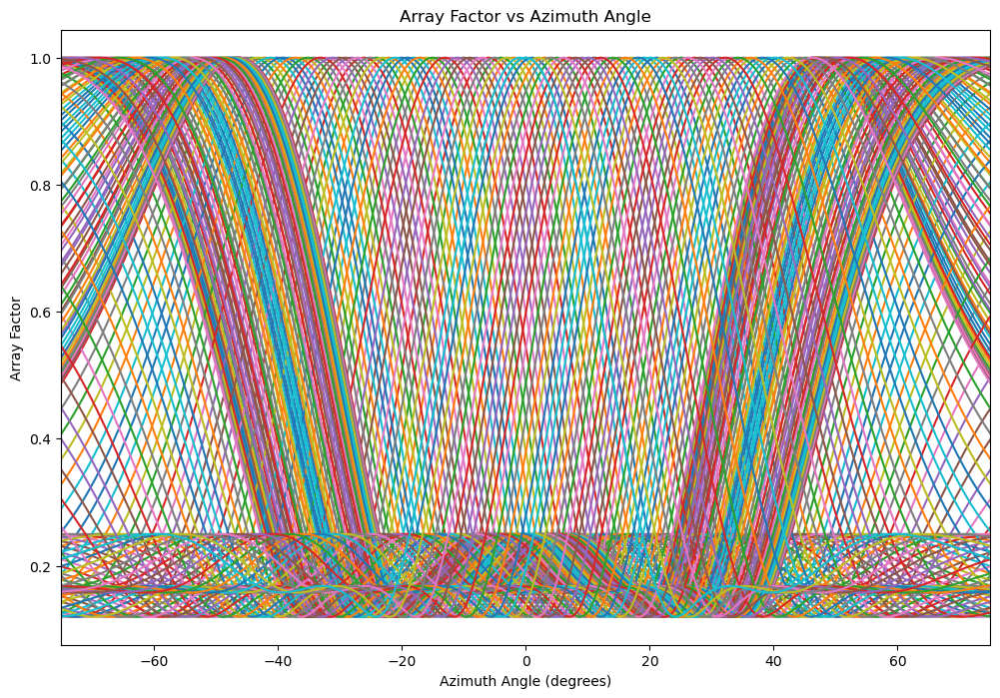

In [3]:
theta_range = np.linspace(-np.pi, np.pi, 180)
elevation_angle = np.deg2rad(0)
all_beams = np.zeros((len(theta_range), 1024), dtype=np.complex128)

spacing = 0.58 * session.frequency / 60.48

for i in range(len(theta_range)):
    antenna_array = AntennaArray()
    for ant in range(32):
        if ant not in valid_antennas:
            continue
        antenna_array.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
                0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)

    antenna_array.set_weights(antenna_array.get_conjugate_beamformer(theta_range[i], elevation_angle))
    af, az, _ = antenna_array.get_array_pattern_azimuth(el=0, N=1024, full=True)
    all_beams[i, :] = af

plt.figure(figsize=(12, 8))
for i in range(len(theta_range)):
    plt.plot(np.rad2deg(az), np.abs(all_beams[i, :]) / np.max(np.abs(all_beams[i, :])))
plt.xlim(-75, 75)
plt.xlabel('Azimuth Angle (degrees)')
plt.ylabel('Array Factor')
plt.title('Array Factor vs Azimuth Angle')

In [4]:
# Initialize array to store classified beam indices
beam_classifications = np.zeros(len(channel_data_avg), dtype=int)

# For each averaged CSI data point
for i in tqdm.tqdm(range(len(channel_data_avg))):
    # Get the CSI weights for this data point
    csi_weights = channel_data_avg[i, :]
    
    # Create antenna array with the valid antennas
    antenna_array = AntennaArray()
    for ant_idx, ant in enumerate(valid_antennas):
        if ant >= len(ordering_sets):
            continue
        antenna_array.add_element(
            ordering_sets[ant, 0] * spacing - np.sign(ordering_sets[ant, 0]) * spacing / 2, 
            0, 
            ordering_sets[ant, 1] * spacing - np.sign(ordering_sets[ant, 1]) * spacing / 2
        )
    
    # Set weights to the CSI data
    antenna_array.set_weights(csi_weights)
    
    # Get the beam pattern for this CSI
    af, az, _ = antenna_array.get_array_pattern_azimuth(el=0, N=1024, full=True)
    
    # Normalize the beam pattern
    af_normalized = af 
    
    main_region = (np.abs(np.rad2deg(az)) <= 60)
    measured_peak_idx = np.argmax(np.abs(af_normalized[main_region]))
    measured_peak_angle = az[main_region][measured_peak_idx]
    
    # Find closest ideal beam peak
    best_angle_diff = np.inf
    best_idx = 0
    
    for beam_idx in range(len(all_beams)):
        ideal_normalized = all_beams[beam_idx, :] / np.max(np.abs(all_beams[beam_idx, :]))
        ideal_peak_idx = np.argmax(np.abs(ideal_normalized[main_region]))
        ideal_peak_angle = az[main_region][ideal_peak_idx]
        
        angle_diff = np.abs(ideal_peak_angle - measured_peak_angle)
        
        if angle_diff < best_angle_diff:
            best_angle_diff = angle_diff
            best_idx = beam_idx
    
    # Store the classification
    beam_classifications[i] = best_idx

print(f"Classified {len(beam_classifications)} data points")
print(f"Beam indices range from {beam_classifications.min()} to {beam_classifications.max()}")
print(f"Unique beams found: {len(np.unique(beam_classifications))}")

  0%|          | 0/112 [00:00<?, ?it/s]

100%|██████████| 112/112 [00:01<00:00, 63.93it/s]

Classified 112 data points
Beam indices range from 0 to 178
Unique beams found: 52


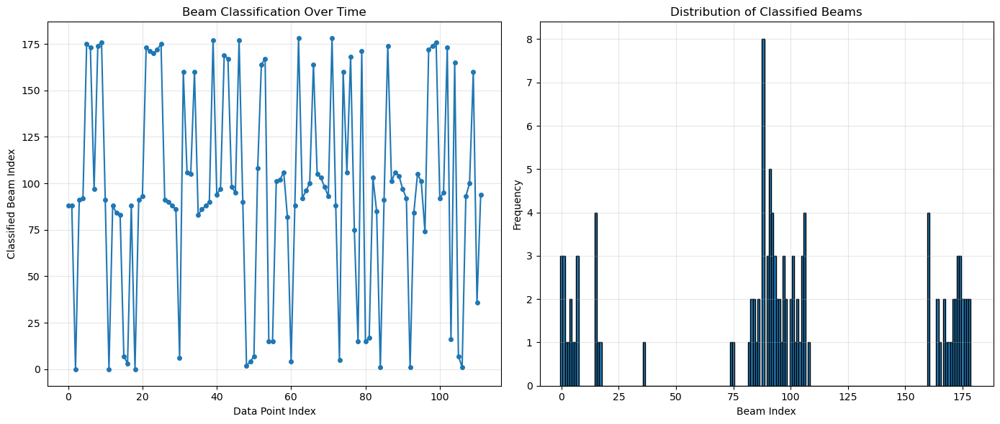


Azimuth angles (degrees):
  Min: -180.00°
  Max: 177.99°
  Mean: 15.93°
  Std: 111.25°


In [5]:
# Visualize the beam classifications over time
plt.figure(figsize=(14, 6))

# Plot 1: Beam index over time
plt.subplot(1, 2, 1)
plt.plot(beam_classifications, 'o-', markersize=4)
plt.xlabel('Data Point Index')
plt.ylabel('Classified Beam Index')
plt.title('Beam Classification Over Time')
plt.grid(True, alpha=0.3)

# Plot 2: Histogram of beam classifications
plt.subplot(1, 2, 2)
plt.hist(beam_classifications, bins=np.arange(0, len(theta_range)+1)-0.5, edgecolor='black')
plt.xlabel('Beam Index')
plt.ylabel('Frequency')
plt.title('Distribution of Classified Beams')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Convert beam indices to azimuth angles
classified_angles = theta_range[beam_classifications]
print(f"\nAzimuth angles (degrees):")
print(f"  Min: {np.rad2deg(classified_angles.min()):.2f}°")
print(f"  Max: {np.rad2deg(classified_angles.max()):.2f}°")
print(f"  Mean: {np.rad2deg(classified_angles.mean()):.2f}°")
print(f"  Std: {np.rad2deg(classified_angles.std()):.2f}°")

In [6]:
# Save the classification results
output_data = {
    'beam_indices': beam_classifications.tolist(),
    'azimuth_angles_rad': classified_angles.tolist(),
    'azimuth_angles_deg': np.rad2deg(classified_angles).tolist(),
    'theta_range_rad': theta_range.tolist(),
    'theta_range_deg': np.rad2deg(theta_range).tolist(),
    'session_id': session.session_id,
    'num_data_points': len(beam_classifications),
    'num_unique_beams': len(np.unique(beam_classifications))
}

# Save to JSON file
output_path = session.session_dir / 'beam_classifications.json'
import json
with open(output_path, 'w') as f:
    json.dump(output_data, f, indent=2)

print(f"Saved classification results to: {output_path}")

# Also save as numpy array for easy loading
np_output_path = session.session_dir / 'beam_classifications.npy'
np.save(np_output_path, beam_classifications)
print(f"Saved numpy array to: {np_output_path}")

Saved classification results to: ..\data\2025-11-20\session_135938\beam_classifications.json
Saved numpy array to: ..\data\2025-11-20\session_135938\beam_classifications.npy


In [6]:
# Create animation to verify each frame
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Pre-compute all beam patterns to speed up animation
print("Pre-computing beam patterns for all data points...")
all_measured_beams = []
for i in tqdm.tqdm(range(len(channel_data_avg))):
    csi_weights = channel_data_avg[i, :]
    
    # Create antenna array and get measured beam pattern
    antenna_array = AntennaArray()
    for ant_idx, ant in enumerate(valid_antennas):
        if ant >= len(ordering_sets):
            continue
        antenna_array.add_element(
            ordering_sets[ant, 0] * spacing - np.sign(ordering_sets[ant, 0]) * spacing / 2, 
            0, 
            ordering_sets[ant, 1] * spacing - np.sign(ordering_sets[ant, 1]) * spacing / 2
        )
    antenna_array.set_weights(csi_weights)
    af, az, _ = antenna_array.get_array_pattern_azimuth(el=0, N=1024, full=True)
    all_measured_beams.append(af)

print("Creating animation...")

# Create figure for animation
fig, ax = plt.subplots(figsize=(12, 6))

# Initialize plot elements
line_measured, = ax.plot([], [], 'b-', linewidth=2.5, label='Measured')
line_ideal, = ax.plot([], [], 'r--', linewidth=2.5, label='Ideal')
ax.set_xlim(-60, 60)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Azimuth Angle (degrees)', fontsize=12)
ax.set_ylabel('Normalized Array Factor', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
title_text = ax.text(0.5, 1.02, '', transform=ax.transAxes, ha='center', fontsize=13, fontweight='bold')

def init():
    line_measured.set_data([], [])
    line_ideal.set_data([], [])
    title_text.set_text('')
    return line_measured, line_ideal, title_text

def update(frame_idx):
    # Get measured beam
    af = all_measured_beams[frame_idx]
    af_normalized = np.abs(af) / np.max(np.abs(af))
    
    # Get classified beam index
    beam_idx = beam_classifications[frame_idx]
    ideal_beam = all_beams[beam_idx, :]
    ideal_normalized = np.abs(ideal_beam) / np.max(np.abs(ideal_beam))
    
    # Update plot data
    line_measured.set_data(np.rad2deg(az), af_normalized)
    line_ideal.set_data(np.rad2deg(az), ideal_normalized)
    
    # Update title with data point info
    title_text.set_text(f'Data Point {frame_idx} / {len(channel_data_avg)-1} | '
                        f'Classified Beam Index: {beam_idx} | '
                        f'Azimuth: {np.rad2deg(theta_range[beam_idx]):.1f}°')
    
    return line_measured, line_ideal, title_text

# Create animation
# Note: interval is in milliseconds (500ms = 0.5 seconds per frame)
anim = FuncAnimation(fig, update, init_func=init, frames=len(channel_data_avg), 
                     interval=500, blit=True, repeat=True)

# Save as GIF (compatible with Pillow writer)
gif_path = session.session_dir / 'plots' / 'beam_classification_animation.gif'
print(f"Saving animation to: {gif_path}")
print("This may take a minute...")
anim.save(gif_path, writer='pillow', fps=2, dpi=100)
print("Animation saved!")

# Display in notebook (if running in Jupyter)
plt.close()
HTML(anim.to_jshtml())

Pre-computing beam patterns for all data points...


100%|██████████| 112/112 [00:01<00:00, 75.33it/s]


Creating animation...
Saving animation to: ..\data\2025-11-25\session_122307\plots\beam_classification_animation.gif
This may take a minute...
Animation saved!


In [22]:
# Try different classification metrics
def classify_with_mse(af_normalized, all_beams):
    """Classify using Mean Squared Error (minimize)"""
    best_mse = np.inf
    best_idx = 0
    
    for beam_idx in range(len(all_beams)):
        ideal_normalized = all_beams[beam_idx, :] / np.max(np.abs(all_beams[beam_idx, :]))
        # MSE on magnitudes
        mse = np.mean((np.abs(af_normalized) - np.abs(ideal_normalized))**2)
        
        if mse < best_mse:
            best_mse = mse
            best_idx = beam_idx
    
    return best_idx, best_mse

def classify_with_peak_location(af_normalized, all_beams, az):
    """Classify by finding beam with peak closest to measured peak"""
    # Find peak of measured beam (in main region -60 to 60 degrees)
    main_region = (np.abs(np.rad2deg(az)) <= 60)
    measured_peak_idx = np.argmax(np.abs(af_normalized[main_region]))
    measured_peak_angle = az[main_region][measured_peak_idx]
    
    # Find closest ideal beam peak
    best_angle_diff = np.inf
    best_idx = 0
    
    for beam_idx in range(len(all_beams)):
        ideal_normalized = all_beams[beam_idx, :] / np.max(np.abs(all_beams[beam_idx, :]))
        ideal_peak_idx = np.argmax(np.abs(ideal_normalized[main_region]))
        ideal_peak_angle = az[main_region][ideal_peak_idx]
        
        angle_diff = np.abs(ideal_peak_angle - measured_peak_angle)
        
        if angle_diff < best_angle_diff:
            best_angle_diff = angle_diff
            best_idx = beam_idx
    
    return best_idx, best_angle_diff

def classify_with_weighted_correlation(af_normalized, all_beams, az, focus_region_deg=60):
    """Classify using correlation with emphasis on main beam region"""
    # Create weight function - higher weight in center region
    weights = np.exp(-np.abs(np.rad2deg(az)) / focus_region_deg)
    weights = weights / np.sum(weights)
    
    best_corr = -np.inf
    best_idx = 0
    
    for beam_idx in range(len(all_beams)):
        ideal_normalized = all_beams[beam_idx, :] / np.max(np.abs(all_beams[beam_idx, :]))
        
        # Weighted correlation
        corr = np.sum(weights * np.abs(af_normalized) * np.abs(ideal_normalized))
        
        if corr > best_corr:
            best_corr = corr
            best_idx = beam_idx
    
    return best_idx, best_corr

def classify_with_cosine_similarity(af_normalized, all_beams):
    """Classify using cosine similarity"""
    best_similarity = -np.inf
    best_idx = 0
    
    af_mag = np.abs(af_normalized)
    
    for beam_idx in range(len(all_beams)):
        ideal_mag = np.abs(all_beams[beam_idx, :] / np.max(np.abs(all_beams[beam_idx, :])))
        
        # Cosine similarity
        similarity = np.dot(af_mag, ideal_mag) / (np.linalg.norm(af_mag) * np.linalg.norm(ideal_mag))
        
        if similarity > best_similarity:
            best_similarity = similarity
            best_idx = beam_idx
    
    return best_idx, best_similarity

print("Classification metric functions defined!")

Classification metric functions defined!


In [23]:
# Compare all metrics on the same dataset
metrics = {
    'Original (Dot Product)': beam_classifications,
    'MSE': np.zeros(len(channel_data_avg), dtype=int),
    'Peak Location': np.zeros(len(channel_data_avg), dtype=int),
    'Weighted Correlation': np.zeros(len(channel_data_avg), dtype=int),
    'Cosine Similarity': np.zeros(len(channel_data_avg), dtype=int)
}

print("Running classification with all metrics...")

for i in tqdm.tqdm(range(len(channel_data_avg))):
    # Get the CSI weights for this data point
    csi_weights = channel_data_avg[i, :]
    
    # Create antenna array with the valid antennas
    antenna_array = AntennaArray()
    for ant_idx, ant in enumerate(valid_antennas):
        if ant >= len(ordering_sets):
            continue
        antenna_array.add_element(
            ordering_sets[ant, 0] * spacing - np.sign(ordering_sets[ant, 0]) * spacing / 2, 
            0, 
            ordering_sets[ant, 1] * spacing - np.sign(ordering_sets[ant, 1]) * spacing / 2
        )
    
    # Set weights to the CSI data
    antenna_array.set_weights(csi_weights)
    
    # Get the beam pattern for this CSI
    af, az, _ = antenna_array.get_array_pattern_azimuth(el=0, N=1024, full=True)
    af_normalized = af / np.max(np.abs(af))
    
    # Try all metrics
    metrics['MSE'][i], _ = classify_with_mse(af_normalized, all_beams)
    metrics['Peak Location'][i], _ = classify_with_peak_location(af_normalized, all_beams, az)
    metrics['Weighted Correlation'][i], _ = classify_with_weighted_correlation(af_normalized, all_beams, az)
    metrics['Cosine Similarity'][i], _ = classify_with_cosine_similarity(af_normalized, all_beams)

print("\nClassification complete!")
print("\nComparison of metrics:")
for metric_name, classifications in metrics.items():
    unique_beams = len(np.unique(classifications))
    print(f"{metric_name:25s}: {unique_beams:3d} unique beams found")

Running classification with all metrics...


100%|██████████| 106/106 [00:02<00:00, 45.47it/s]


Classification complete!

Comparison of metrics:
Original (Dot Product)   :  56 unique beams found
MSE                      :  66 unique beams found
Peak Location            :  66 unique beams found
Weighted Correlation     :  70 unique beams found
Cosine Similarity        :  72 unique beams found


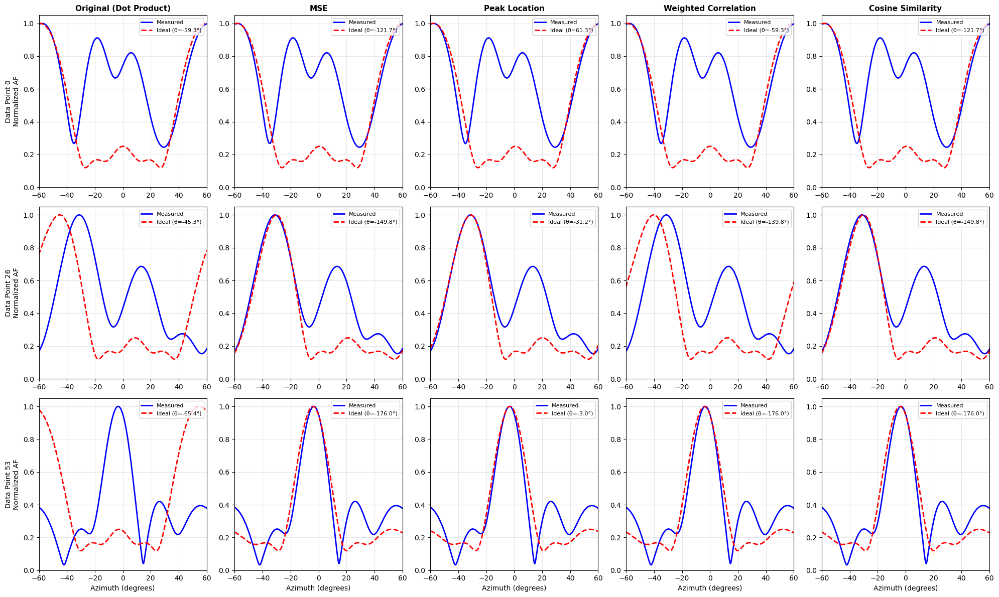

Saved comparison plot to: ..\data\2025-11-20\session_135938\plots\metric_comparison.png


In [24]:
# Visual comparison of different metrics on example data points
example_data_points = [0, 26, 53]  # The problematic ones from your screenshot

fig, axes = plt.subplots(len(example_data_points), len(metrics), figsize=(20, 12))

for row_idx, data_idx in enumerate(example_data_points):
    # Get the CSI weights
    csi_weights = channel_data_avg[data_idx, :]
    
    # Create antenna array and get measured beam pattern
    antenna_array = AntennaArray()
    for ant_idx, ant in enumerate(valid_antennas):
        if ant >= len(ordering_sets):
            continue
        antenna_array.add_element(
            ordering_sets[ant, 0] * spacing - np.sign(ordering_sets[ant, 0]) * spacing / 2, 
            0, 
            ordering_sets[ant, 1] * spacing - np.sign(ordering_sets[ant, 1]) * spacing / 2
        )
    antenna_array.set_weights(csi_weights)
    af, az, _ = antenna_array.get_array_pattern_azimuth(el=0, N=1024, full=True)
    
    # Plot for each metric
    for col_idx, (metric_name, classifications) in enumerate(metrics.items()):
        ax = axes[row_idx, col_idx]
        
        # Get the classified beam index for this metric
        beam_idx = classifications[data_idx]
        
        # Plot measured and ideal beams
        ax.plot(np.rad2deg(az), np.abs(af) / np.max(np.abs(af)), 'b-', linewidth=2, label='Measured')
        ax.plot(np.rad2deg(az), np.abs(all_beams[beam_idx, :]) / np.max(np.abs(all_beams[beam_idx, :])), 
                'r--', linewidth=2, label=f'Ideal (θ={np.rad2deg(theta_range[beam_idx]):.1f}°)')
        ax.set_xlim(-60, 60)
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.3)
        
        # Labels
        if row_idx == len(example_data_points) - 1:
            ax.set_xlabel('Azimuth (degrees)')
        if col_idx == 0:
            ax.set_ylabel(f'Data Point {data_idx}\nNormalized AF')
        if row_idx == 0:
            ax.set_title(metric_name, fontsize=11, fontweight='bold')
        
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(session.session_dir / 'plots' / 'metric_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Saved comparison plot to: {session.session_dir / 'plots' / 'metric_comparison.png'}")

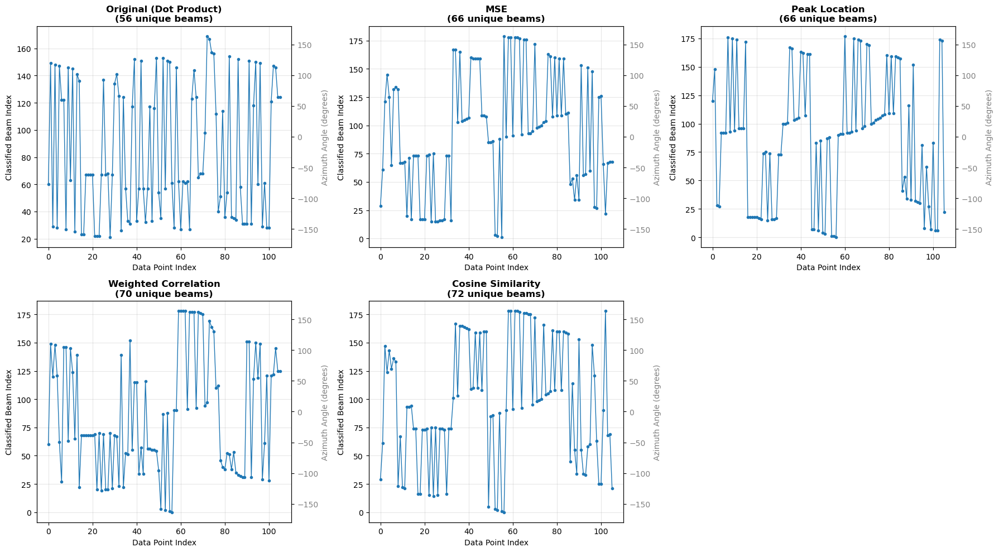

Saved distribution comparison to: ..\data\2025-11-20\session_135938\plots\metric_distributions.png


In [25]:
# Compare distributions of all metrics
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (metric_name, classifications) in enumerate(metrics.items()):
    ax = axes[idx]
    
    # Plot beam index over time
    ax.plot(classifications, 'o-', markersize=3, linewidth=1)
    ax.set_xlabel('Data Point Index')
    ax.set_ylabel('Classified Beam Index')
    ax.set_title(f'{metric_name}\n({len(np.unique(classifications))} unique beams)', fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add angle range on secondary y-axis
    ax2 = ax.twinx()
    classified_angles = theta_range[classifications]
    ax2.plot(classifications, 'o-', markersize=3, linewidth=1, alpha=0)  # invisible plot
    ax2.set_ylabel('Azimuth Angle (degrees)', color='gray')
    ax2.set_ylim(np.rad2deg(theta_range[0]), np.rad2deg(theta_range[-1]))
    ax2.tick_params(axis='y', labelcolor='gray')

# Hide the last subplot if we have fewer than 6 metrics
if len(metrics) < 6:
    axes[-1].axis('off')

plt.tight_layout()
plt.savefig(session.session_dir / 'plots' / 'metric_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Saved distribution comparison to: {session.session_dir / 'plots' / 'metric_distributions.png'}")

In [ ]:
# Choose your preferred metric and save those results
# Options: 'Original (Dot Product)', 'MSE', 'Peak Location', 'Weighted Correlation', 'Cosine Similarity'
preferred_metric = 'Peak Location'  # Change this to your preferred metric

beam_classifications_final = metrics[preferred_metric]
classified_angles = theta_range[beam_classifications_final]

print(f"Selected metric: {preferred_metric}")
print(f"Unique beams: {len(np.unique(beam_classifications_final))}")
print(f"Angle range: {np.rad2deg(classified_angles.min()):.1f}° to {np.rad2deg(classified_angles.max()):.1f}°")

# Save the results
output_data = {
    'classification_metric': preferred_metric,
    'beam_indices': beam_classifications_final.tolist(),
    'azimuth_angles_rad': classified_angles.tolist(),
    'azimuth_angles_deg': np.rad2deg(classified_angles).tolist(),
    'theta_range_rad': theta_range.tolist(),
    'theta_range_deg': np.rad2deg(theta_range).tolist(),
    'session_id': session.session_id,
    'num_data_points': len(beam_classifications_final),
    'num_unique_beams': len(np.unique(beam_classifications_final)),
    'all_metrics': {name: cls.tolist() for name, cls in metrics.items()}
}

# Save to JSON file
output_path = session.session_dir / f'beam_classifications_{preferred_metric.replace(" ", "_").lower()}.json'
import json
with open(output_path, 'w') as f:
    json.dump(output_data, f, indent=2)

print(f"\nSaved classification results to: {output_path}")

# Also save as numpy array for easy loading
np_output_path = session.session_dir / f'beam_classifications_{preferred_metric.replace(" ", "_").lower()}.npy'
np.save(np_output_path, beam_classifications_final)
print(f"Saved numpy array to: {np_output_path}")